In [0]:
import boto3
import os
from pyspark.sql import functions as F

AWS_ACCESS_KEY_ID = "<YOUR_ACCESS_KEY>"        # use your nyc-taxi IAM user's key
AWS_SECRET_ACCESS_KEY = "<YUOR_SECREAT_ACCESS_KEY>"
RAW_BUCKET = "nyc-taxi-raw-machindra-2026"
PROCESSED_BUCKET = "nyc-taxi-processed-machindra-2026"
REGION = "ap-south-1"

s3_client = boto3.client(
    "s3",
    aws_access_key_id=AWS_ACCESS_KEY_ID,
    aws_secret_access_key=AWS_SECRET_ACCESS_KEY,
    region_name=REGION
)

print("boto3 client ready.")

boto3 client ready.


List raw files in S3

In [0]:
response = s3_client.list_objects_v2(Bucket=RAW_BUCKET, Prefix="raw-trips/")
files = [obj["Key"] for obj in response.get("Contents", []) if obj["Key"].endswith(".parquet")]
print(f"Found {len(files)} files:")
for f in files:
    print(" ", f)

Found 12 files:
  raw-trips/yellow_tripdata_2024-01.parquet
  raw-trips/yellow_tripdata_2024-02.parquet
  raw-trips/yellow_tripdata_2024-03.parquet
  raw-trips/yellow_tripdata_2024-04.parquet
  raw-trips/yellow_tripdata_2024-05.parquet
  raw-trips/yellow_tripdata_2024-06.parquet
  raw-trips/yellow_tripdata_2024-07.parquet
  raw-trips/yellow_tripdata_2024-08.parquet
  raw-trips/yellow_tripdata_2024-09.parquet
  raw-trips/yellow_tripdata_2024-10.parquet
  raw-trips/yellow_tripdata_2024-11.parquet
  raw-trips/yellow_tripdata_2024-12.parquet


Define the per-month processing function:

Run it across all 12 months

In [0]:
import boto3, os, pandas as pd, numpy as np, io

# ----- CONFIG -----
BUCKET_RAW = "nyc-taxi-raw-machindra-2026"
BUCKET_PROCESSED = "nyc-taxi-processed-machindra-2026"
WORK_DIR = r"/Workspace/nyc_taxi_tmp"
os.makedirs(WORK_DIR, exist_ok=True)

s3_client = boto3.client(
    "s3", region_name="ap-south-1",
    aws_access_key_id="<YOUR_ACCESS_KEY>",
    aws_secret_access_key="<YOUR_SECRATE_ACCESS_KEY"
)

COLS = [
    "VendorID","tpep_pickup_datetime","tpep_dropoff_datetime",
    "passenger_count","trip_distance","PULocationID","DOLocationID",
    "payment_type","fare_amount","tip_amount","total_amount"
]

FILES = [
    "raw-trips/yellow_tripdata_2024-01.parquet",
    "raw-trips/yellow_tripdata_2024-02.parquet",
    "raw-trips/yellow_tripdata_2024-03.parquet",
    "raw-trips/yellow_tripdata_2024-04.parquet",
    "raw-trips/yellow_tripdata_2024-05.parquet",
    "raw-trips/yellow_tripdata_2024-06.parquet",
    "raw-trips/yellow_tripdata_2024-07.parquet",
    "raw-trips/yellow_tripdata_2024-08.parquet",
    "raw-trips/yellow_tripdata_2024-09.parquet",
    "raw-trips/yellow_tripdata_2024-10.parquet",
    "raw-trips/yellow_tripdata_2024-11.parquet",
    "raw-trips/yellow_tripdata_2024-12.parquet"
]

# ----- LOOP ALL 12 -----
for s3_key in FILES:
    fname = s3_key.split("/")[-1]
    print(f"\n{'='*60}")
    print(f"=== {fname} ===")
    
    local_raw = os.path.join(WORK_DIR, f"raw_{fname}")
    s3_client.download_file(BUCKET_RAW, s3_key, local_raw)
    
    pdf = pd.read_parquet(local_raw, columns=COLS)
    raw_n = len(pdf)
    print(f"Raw: {raw_n:,}")
    
    # Cleaning
    pdf = pdf.dropna(subset=["tpep_pickup_datetime","tpep_dropoff_datetime","trip_distance","fare_amount"])
    pdf = pdf[(pdf["trip_distance"]>0)&(pdf["trip_distance"]<=100)]
    pdf = pdf[(pdf["fare_amount"]>0)&(pdf["fare_amount"]<=500)]
    pdf = pdf[(pdf["passenger_count"]>=1)&(pdf["passenger_count"]<=6)]
    pdf = pdf[pdf["tpep_dropoff_datetime"] > pdf["tpep_pickup_datetime"]]
    pdf["trip_duration_minutes"] = (pdf["tpep_dropoff_datetime"]-pdf["tpep_pickup_datetime"]).dt.total_seconds()/60.0
    pdf = pdf[(pdf["trip_duration_minutes"]>0)&(pdf["trip_duration_minutes"]<=180)]
    
    # STRICT YEAR FILTER (fixes bad folder leak)
    pdf["pickup_year"] = pdf["tpep_pickup_datetime"].dt.year
    pdf = pdf[pdf["pickup_year"] == 2024]
    
    pdf["pickup_month"] = pdf["tpep_pickup_datetime"].dt.month
    pdf["pickup_hour"] = pdf["tpep_pickup_datetime"].dt.hour
    pdf["pickup_dayofweek"] = pdf["tpep_pickup_datetime"].dt.day_name()
    
    clean_n = len(pdf)
    print(f"Clean: {clean_n:,} | Dropped: {raw_n-clean_n:,}")
    pdf.attrs = {}
    
    # Upload partitions
    uploaded = 0
    for (yr, mo), grp in pdf.groupby(["pickup_year","pickup_month"]):
        grp_copy = grp.copy()
        grp_copy.attrs = {}
        buf = io.BytesIO()
        grp_copy.to_parquet(buf, index=False, engine="pyarrow")
        buf.seek(0)
        out_key = f"processed-trips/pickup_year={yr}/pickup_month={mo}/part-{fname.replace('.parquet','')}.parquet"
        s3_client.put_object(Bucket=BUCKET_PROCESSED, Key=out_key, Body=buf.getvalue())
        uploaded += 1
        print(f"  -> uploaded year={yr}/month={mo}")
    
    os.remove(local_raw)
    del pdf
    print(f"=== Done: {fname} ({uploaded} partition file(s)) ===")

print("\n=== ALL 12 MONTHS COMPLETE ===")


=== yellow_tripdata_2024-01.parquet ===
Raw: 2,964,624
Clean: 2,721,704 | Dropped: 242,920
  -> uploaded year=2024/month=1
  -> uploaded year=2024/month=2
=== Done: yellow_tripdata_2024-01.parquet (2 partition file(s)) ===

=== yellow_tripdata_2024-02.parquet ===
Raw: 3,007,526
Clean: 2,717,696 | Dropped: 289,830
  -> uploaded year=2024/month=1
  -> uploaded year=2024/month=2
  -> uploaded year=2024/month=3
=== Done: yellow_tripdata_2024-02.parquet (3 partition file(s)) ===

=== yellow_tripdata_2024-03.parquet ===
Raw: 3,582,628
Clean: 3,033,912 | Dropped: 548,716
  -> uploaded year=2024/month=2
  -> uploaded year=2024/month=3
  -> uploaded year=2024/month=4
=== Done: yellow_tripdata_2024-03.parquet (3 partition file(s)) ===

=== yellow_tripdata_2024-04.parquet ===
Raw: 3,514,289
Clean: 2,985,506 | Dropped: 528,783
  -> uploaded year=2024/month=3
  -> uploaded year=2024/month=4
  -> uploaded year=2024/month=5
=== Done: yellow_tripdata_2024-04.parquet (3 partition file(s)) ===

=== yel

Download processed data locally and load into Spark

In [0]:
import os, shutil

LOCAL_PROCESSED_DIR = "/Workspace/nyc_taxi_processed"
shutil.rmtree(LOCAL_PROCESSED_DIR, ignore_errors=True)
os.makedirs(LOCAL_PROCESSED_DIR, exist_ok=True)

paginator = s3_client.get_paginator("list_objects_v2")
count = 0
for page in paginator.paginate(Bucket=BUCKET_PROCESSED, Prefix="processed-trips/pickup_year=2024/"):
    for obj in page.get("Contents", []):
        if obj["Key"].endswith(".parquet"):
            local_path = os.path.join(LOCAL_PROCESSED_DIR, obj["Key"].replace("/", "_"))
            s3_client.download_file(BUCKET_PROCESSED, obj["Key"], local_path)
            count += 1

print(f"Downloaded {count} files")

Downloaded 34 files


Session Restart

In [0]:
import boto3
import os

# Re-define the path (same one used before, don't re-download)
LOCAL_PROCESSED_DIR = "/Workspace/nyc_taxi_processed"

BUCKET_PROCESSED = "nyc-taxi-processed-machindra-2026"
s3_client = boto3.client(
    "s3", region_name="ap-south-1",
    aws_access_key_id="<ACCESS_KEY>",
    aws_secret_access_key="<SECRATE_ACCESS_KEY"
)

print("Spark check:", spark.version)

# Confirm the files are still physically there
files_on_disk = [f for f in os.listdir(LOCAL_PROCESSED_DIR) if f.endswith(".parquet")]
print(f"Files found on disk: {len(files_on_disk)}")

Spark check: 4.2.0
Files found on disk: 34



Load into Spark + create temp view

In [0]:
df_taxi = spark.read.parquet(LOCAL_PROCESSED_DIR)
df_taxi.createOrReplaceTempView("taxi_trips")

count = df_taxi.count()
print(f"Total rows: {count:,}")

Total rows: 35,602,075


In [0]:
# Query A: Average fare by pickup hour
print("=== A. Average Fare by Pickup Hour ===")
spark.sql("""
SELECT pickup_hour, 
       ROUND(AVG(fare_amount), 2) AS avg_fare,
       COUNT(*) AS trip_count
FROM taxi_trips
GROUP BY pickup_hour
ORDER BY pickup_hour
""").show(24, truncate=False)

# Query B: Top 10 Busiest Pickup Zones
print("=== B. Top 10 Busiest Pickup Zones ===")
spark.sql("""
SELECT PULocationID,
       COUNT(*) AS total_trips,
       ROUND(AVG(fare_amount), 2) AS avg_fare,
       ROUND(AVG(trip_distance), 2) AS avg_distance
FROM taxi_trips
GROUP BY PULocationID
ORDER BY total_trips DESC
LIMIT 10
""").show(truncate=False)

# Query C: Monthly Revenue Trend
print("=== C. Monthly Revenue Trend ===")
spark.sql("""
SELECT pickup_year, pickup_month,
       COUNT(*) AS total_trips,
       ROUND(SUM(total_amount), 2) AS total_revenue,
       ROUND(AVG(fare_amount), 2) AS avg_fare_per_trip
FROM taxi_trips
GROUP BY pickup_year, pickup_month
ORDER BY pickup_year, pickup_month
""").show(12, truncate=False)

# Query D: Trip Metrics by Day of Week
print("=== D. Trip Metrics by Day of Week ===")
spark.sql("""
SELECT pickup_dayofweek,
       ROUND(AVG(trip_distance), 3) AS avg_distance_miles,
       ROUND(AVG(trip_duration_minutes), 2) AS avg_duration_min,
       COUNT(*) AS trip_count
FROM taxi_trips
GROUP BY pickup_dayofweek
ORDER BY 
  CASE pickup_dayofweek
    WHEN 'Monday' THEN 1 WHEN 'Tuesday' THEN 2 WHEN 'Wednesday' THEN 3
    WHEN 'Thursday' THEN 4 WHEN 'Friday' THEN 5 WHEN 'Saturday' THEN 6
    WHEN 'Sunday' THEN 7
  END
""").show(truncate=False)

# Query E: Average Tip % by Payment Type
print("=== E. Average Tip % by Payment Type ===")
spark.sql("""
SELECT payment_type,
       ROUND(AVG((tip_amount / NULLIF(total_amount, 0)) * 100), 2) AS avg_tip_percent,
       COUNT(*) AS trip_count,
       ROUND(AVG(tip_amount), 2) AS avg_tip_amount,
       ROUND(AVG(total_amount), 2) AS avg_total_amount
FROM taxi_trips
GROUP BY payment_type
ORDER BY avg_tip_percent DESC
""").show(truncate=False)

=== A. Average Fare by Pickup Hour ===
+-----------+--------+----------+
|pickup_hour|avg_fare|trip_count|
+-----------+--------+----------+
|0          |20.3    |953965    |
|1          |18.07   |622850    |
|2          |16.57   |405575    |
|3          |17.58   |259833    |
|4          |23.82   |166716    |
|5          |28.51   |195979    |
|6          |23.13   |458307    |
|7          |19.53   |926658    |
|8          |18.56   |1301061   |
|9          |18.64   |1507626   |
|10         |19.03   |1663005   |
|11         |19.29   |1805935   |
|12         |19.72   |1959627   |
|13         |20.45   |2031940   |
|14         |21.24   |2181758   |
|15         |21.22   |2248881   |
|16         |21.29   |2282312   |
|17         |19.73   |2454953   |
|18         |18.44   |2555704   |
|19         |18.59   |2253271   |
|20         |18.96   |2043406   |
|21         |19.04   |2066831   |
|22         |19.65   |1857890   |
|23         |20.95   |1397992   |
+-----------+--------+----------+

=== B. T

In [0]:
df_taxi.write.format("delta").mode("overwrite").saveAsTable("taxi_trips_dashboard")
print("Delta table 'taxi_trips_dashboard' created for Dashboard use")

# Verify
spark.sql("SELECT COUNT(*) FROM taxi_trips_dashboard").show()

Delta table 'taxi_trips_dashboard' created for Dashboard use
+--------+
|COUNT(*)|
+--------+
|35602075|
+--------+



In [0]:
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import pandas as pd

plt.style.use("seaborn-v0_8-darkgrid")
plt.rcParams["figure.figsize"] = (12, 5)
plt.rcParams["axes.titlesize"] = 14
plt.rcParams["axes.labelsize"] = 12

Average Fare by Pickup Hour

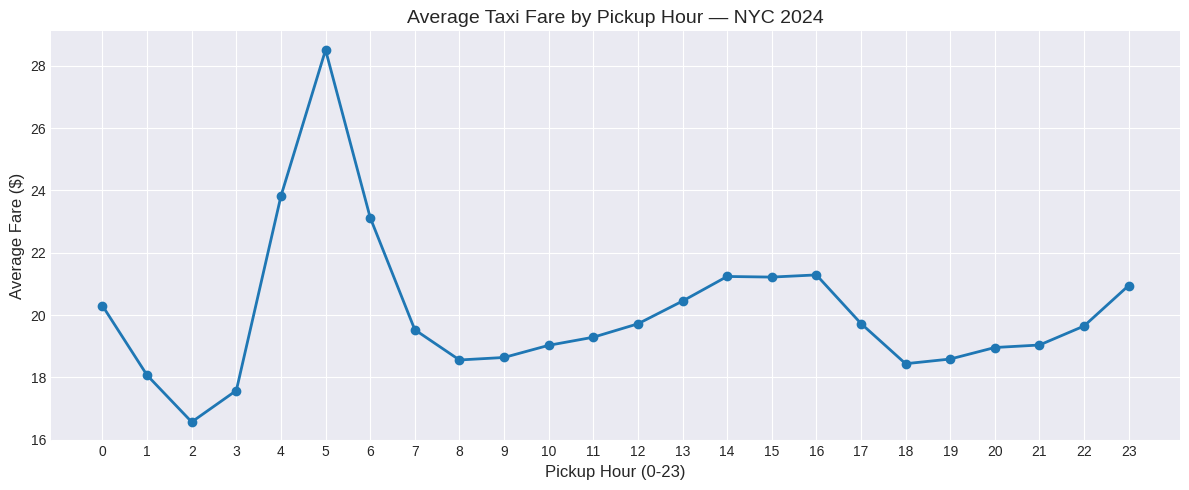

In [0]:
pdf_hourly = spark.sql("""
SELECT pickup_hour, ROUND(AVG(fare_amount),2) AS avg_fare
FROM taxi_trips_dashboard
GROUP BY pickup_hour ORDER BY pickup_hour
""").toPandas()
pdf_hourly.attrs = {}

plt.figure(figsize=(12, 5))
plt.plot(pdf_hourly["pickup_hour"], pdf_hourly["avg_fare"], marker="o", color="#1f77b4", linewidth=2)
plt.xticks(range(0, 24))
plt.xlabel("Pickup Hour (0-23)")
plt.ylabel("Average Fare ($)")
plt.title("Average Taxi Fare by Pickup Hour — NYC 2024")
plt.tight_layout()
plt.show()

Top 10 Busiest Pickup Zones

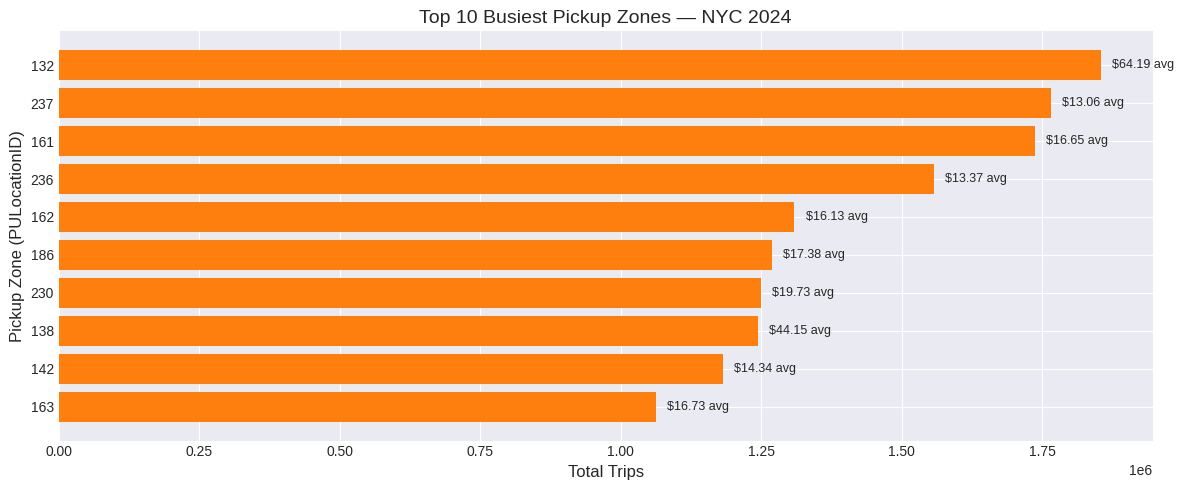

In [0]:
pdf_zones = spark.sql("""
SELECT PULocationID, COUNT(*) AS total_trips, ROUND(AVG(fare_amount),2) AS avg_fare
FROM taxi_trips_dashboard
GROUP BY PULocationID ORDER BY total_trips DESC LIMIT 10
""").toPandas()
pdf_zones.attrs = {}
pdf_zones["zone_label"] = pdf_zones["PULocationID"].astype(str)

plt.figure(figsize=(12, 5))
bars = plt.barh(pdf_zones["zone_label"], pdf_zones["total_trips"], color="#ff7f0e")
plt.gca().invert_yaxis()
plt.xlabel("Total Trips")
plt.ylabel("Pickup Zone (PULocationID)")
plt.title("Top 10 Busiest Pickup Zones — NYC 2024")

for bar, fare in zip(bars, pdf_zones["avg_fare"]):
    plt.text(bar.get_width() + 20000, bar.get_y() + bar.get_height()/2,
             f"${fare} avg", va="center", fontsize=9)
plt.tight_layout()
plt.show()

Monthly Revenue Trend

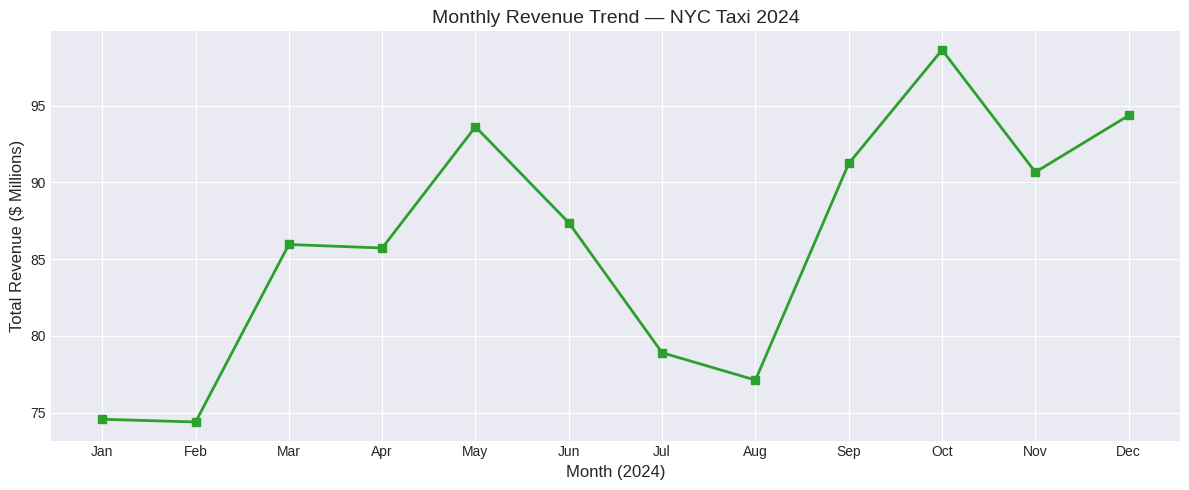

In [0]:
pdf_monthly = spark.sql("""
SELECT pickup_month, SUM(total_amount) AS total_revenue, COUNT(*) AS total_trips
FROM taxi_trips_dashboard
GROUP BY pickup_year, pickup_month ORDER BY pickup_month
""").toPandas()
pdf_monthly.attrs = {}

plt.figure(figsize=(12, 5))
plt.plot(pdf_monthly["pickup_month"], pdf_monthly["total_revenue"]/1e6,
         marker="s", color="#2ca02c", linewidth=2)
plt.xticks(range(1, 13), ["Jan","Feb","Mar","Apr","May","Jun","Jul","Aug","Sep","Oct","Nov","Dec"])
plt.xlabel("Month (2024)")
plt.ylabel("Total Revenue ($ Millions)")
plt.title("Monthly Revenue Trend — NYC Taxi 2024")
plt.tight_layout()
plt.show()

Trips by Day of Week

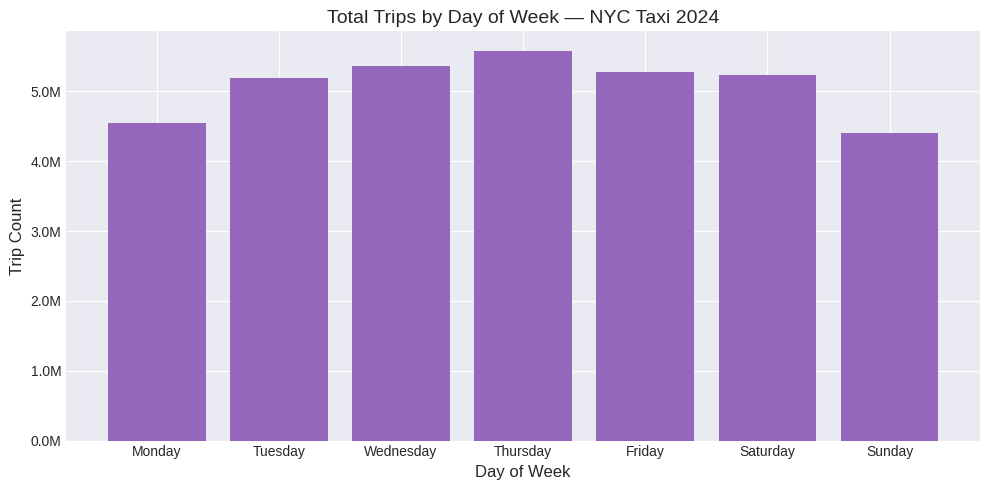

In [0]:
pdf_dow = spark.sql("""
SELECT pickup_dayofweek, COUNT(*) AS trip_count
FROM taxi_trips_dashboard
GROUP BY pickup_dayofweek
ORDER BY CASE pickup_dayofweek
  WHEN 'Monday' THEN 1 WHEN 'Tuesday' THEN 2 WHEN 'Wednesday' THEN 3
  WHEN 'Thursday' THEN 4 WHEN 'Friday' THEN 5 WHEN 'Saturday' THEN 6
  WHEN 'Sunday' THEN 7 END
""").toPandas()
pdf_dow.attrs = {}

plt.figure(figsize=(10, 5))
plt.bar(pdf_dow["pickup_dayofweek"], pdf_dow["trip_count"], color="#9467bd")
plt.xlabel("Day of Week")
plt.ylabel("Trip Count")
plt.title("Total Trips by Day of Week — NYC Taxi 2024")
plt.gca().yaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f"{x/1e6:.1f}M"))
plt.tight_layout()
plt.show()

Tip % by Payment Type

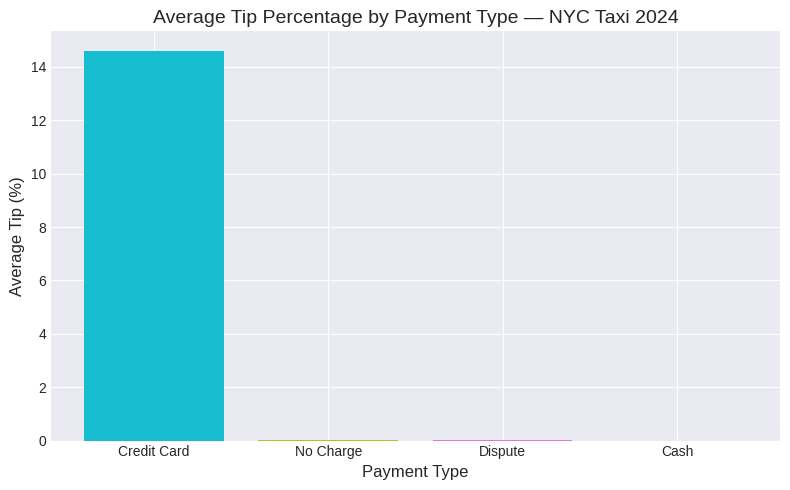

In [0]:
pdf_tip = spark.sql("""
SELECT payment_type,
       ROUND(AVG((tip_amount/NULLIF(total_amount,0))*100),2) AS avg_tip_percent
FROM taxi_trips_dashboard
GROUP BY payment_type ORDER BY avg_tip_percent DESC
""").toPandas()
pdf_tip.attrs = {}

# Map payment type codes to labels
pay_labels = {1: "Credit Card", 2: "Cash", 3: "No Charge", 4: "Dispute"}
pdf_tip["payment_label"] = pdf_tip["payment_type"].map(pay_labels).fillna(pdf_tip["payment_type"].astype(str))

plt.figure(figsize=(8, 5))
plt.bar(pdf_tip["payment_label"], pdf_tip["avg_tip_percent"], color=["#17becf","#bcbd22","#e377c2","#7f7f7f"])
plt.xlabel("Payment Type")
plt.ylabel("Average Tip (%)")
plt.title("Average Tip Percentage by Payment Type — NYC Taxi 2024")
plt.tight_layout()
plt.show()

Trip Distance Distribution by Day of Week

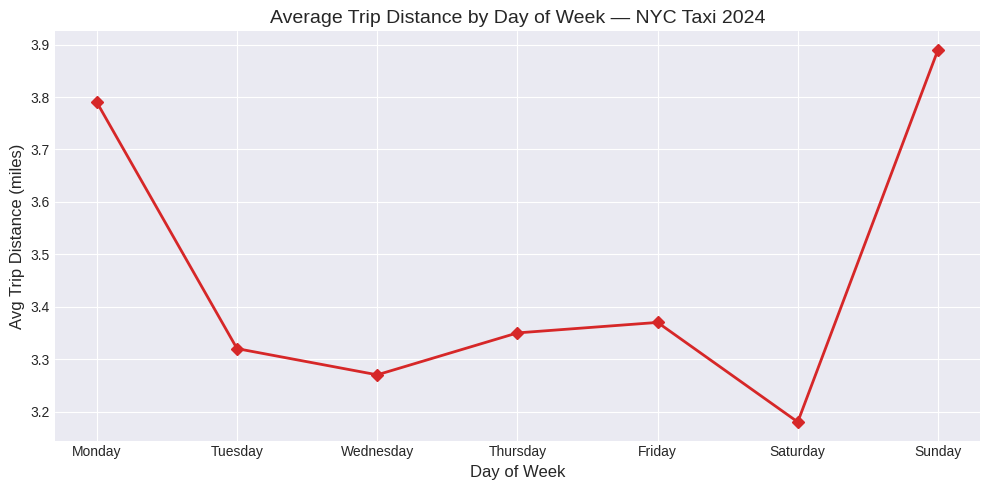

In [0]:
pdf_dist = spark.sql("""
SELECT pickup_dayofweek, ROUND(AVG(trip_distance),2) AS avg_distance
FROM taxi_trips_dashboard
GROUP BY pickup_dayofweek
ORDER BY CASE pickup_dayofweek
  WHEN 'Monday' THEN 1 WHEN 'Tuesday' THEN 2 WHEN 'Wednesday' THEN 3
  WHEN 'Thursday' THEN 4 WHEN 'Friday' THEN 5 WHEN 'Saturday' THEN 6
  WHEN 'Sunday' THEN 7 END
""").toPandas()
pdf_dist.attrs = {}

plt.figure(figsize=(10, 5))
plt.plot(pdf_dist["pickup_dayofweek"], pdf_dist["avg_distance"],
         marker="D", color="#d62728", linewidth=2)
plt.xlabel("Day of Week")
plt.ylabel("Avg Trip Distance (miles)")
plt.title("Average Trip Distance by Day of Week — NYC Taxi 2024")
plt.tight_layout()
plt.show()